# 06. A.X Encoder 추가와 감정 후처리 (라벨 묶기 · 부정 편향 보정)

1. **A.X Encoder**(SKT, ModernBERT, 149M)를 같은 조건으로 학습해 기존 모델·앙상블과 비교한다.
2. **후처리**(모델 재학습 없음): 모델이 낸 44개 감정 확률을
   - **계층적으로 묶는다**: 44개 감정 → 10개 그룹 + ‘없음’ → 3개 정서(긍정·부정·중립)
   - **부정 편향을 보정한다**: KOTE(댓글)의 감정 빈도에 맞춰진 확률을 서비스(일기) 분포에 맞게 사전확률 보정

**미리 정한 규칙**
- A.X 학습률: validation 라벨 macro-F1이 높은 쪽
- 서비스용 앙상블: 3개 이하 모델 후보 중 validation 그룹 macro-F1 최고
- 모든 threshold는 validation(보정 전)에서 정하고 test에 그대로 적용한다.

코드: `ai/src/emotion/postprocess.py` · 설정: `ai/configs/emotion_postprocess.json`

## 1. 환경과 결과 불러오기

In [1]:
import os
import sys
import json
import platform
from pathlib import Path


def find_ai_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 ai/ 폴더를 찾는다(저장소 루트·ai/·ai/notebooks/ 모두 지원)."""
    for p in [start, *start.parents]:
        if p.name == "ai" and (p / "src" / "data" / "paths.py").is_file():
            return p
        if (p / "ai" / "src" / "data" / "paths.py").is_file():
            return p / "ai"
    raise FileNotFoundError("ai/ 폴더를 찾지 못했습니다. 저장소 안에서 실행하세요.")


AI_ROOT = find_ai_root(Path.cwd().resolve())
if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

# 커널 점검: 저장소 .venv(학습 패키지 포함)가 아니면 여기서 멈추고 안내한다.
from src.env_check import assert_environment
ENV = assert_environment(AI_ROOT / "requirements-train.txt", AI_ROOT.parent)

from src.data.paths import get_paths, configure_hf_cache, load_json

P = get_paths(AI_ROOT)
configure_hf_cache(P)                       # transformers import 전에 호출
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"


def rel(p) -> str:
    return Path(p).resolve().relative_to(P.repo_root).as_posix()

Python 3.13.5 | 저장소 .venv 커널 사용: 예
  numpy            필요 2.5.3      설치 2.5.3            OK
  pandas           필요 3.0.6      설치 3.0.6            OK
  pyarrow          필요 25.0.1     설치 25.0.1           OK
  matplotlib       필요 3.11.2     설치 3.11.2           OK
  huggingface_hub  필요 1.33.0     설치 1.33.0           OK
  transformers     필요 5.19.0     설치 5.19.0           OK
  ipykernel        필요 7.4.0      설치 7.4.0            OK
  torch            필요 2.14.1+cu130 설치 2.14.1+cu130     OK


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
ANALYSIS_CFG = load_json(P.configs / "analysis.json")
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((f for f in ANALYSIS_CFG["figure"]["korean_font_candidates"] if f in installed_fonts), None)
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
else:
    print("경고: 한글 글꼴을 찾지 못했습니다.")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["figure.dpi"] = ANALYSIS_CFG["figure"]["dpi"]
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]


def show_fmt(df: pd.DataFrame, formats: dict, index: bool = True):
    """열별 표시 형식만 바꿔 보여준다(원본 DataFrame은 그대로)."""
    d = df.copy()
    for c, f in formats.items():
        d[c] = d[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    display(d if index else d.reset_index(drop=True))


def save_fig(fig, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fig.savefig(path, bbox_inches="tight", facecolor=fig.get_facecolor())
    missing = [x for x in w if "missing from font" in str(x.message)]
    print(f"그림 저장: {rel(path)}" + (f" | 글꼴 누락 경고 {len(missing)}건" if missing else " | 글꼴 누락 없음"))

from collections import Counter
from src.data.labels import load_label_names
from src.data.kote_load import load_raw_annotations
from src.emotion import metrics as M
from src.emotion.targets import vote_fractions
from src.emotion.postprocess import (VALENCES, hierarchy, group_scores, valence_scores, load_postprocess,
                                     target_priors_valence_balanced, adjust_priors, estimate_priors_em)

LABELS = load_label_names(P.configs / "kote_labels.json")
PP = load_postprocess(P.configs / "emotion_postprocess.json")
H = hierarchy(PP, LABELS)
PI_TRAIN = np.array(PP["train_priors"]["values"])
VAL_KO = {"positive": "긍정", "negative": "부정", "neutral": "중립"}
EMO_OUT = P.ai_root / "outputs" / "emotion"
OUT = EMO_OUT / "postprocess"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
GRID = M.threshold_grid(0.02, 0.95, 0.01)


def load_probs(rid):
    d = EMO_OUT / rid
    return {s: np.load(d / f"{s}_probs.npy") for s in ("validation", "test")}, \
           {s: pd.read_csv(d / f"{s}_ids.csv", dtype=str)["ID"].tolist() for s in ("validation", "test")}


RUN_IDS = ["baseline_v2021_s42", "klue_roberta_large_s42", "kl_bin_s43", "kl_bin_s44", "kl_mtsoft_s42",
           "kc_mtsoft_s42", "kc_mtsoft_s43", "kc_mtsoft_s44", "ax_bin_lr2e5_s42", "ax_bin_lr5e5_s42"]
PROBS, IDS = {}, None
for rid in RUN_IDS:
    if (EMO_OUT / rid / "metrics.json").exists():
        PROBS[rid], ids = load_probs(rid)
        IDS = IDS or ids
        assert ids == IDS, rid
print("불러온 실행:", list(PROBS))

# 정답: 라벨(44) / 그룹(11, OR) / 정서(3, OR)
Y = {s: np.load(EMO_OUT / "baseline_v2021_s42" / f"{s}_labels.npy").astype(np.int8) for s in ("validation", "test")}
YG = {s: group_scores(Y[s], H).astype(np.int8) for s in Y}
YV = {s: valence_scores(Y[s], H).astype(np.int8) for s in Y}

# 평가자 투표로 정한 '주 그룹'·'주 정서'(동점 허용)
raw = load_raw_annotations(P.raw_kote)
VOTES = {s: vote_fractions(raw, IDS[s], LABELS) * 5 for s in IDS}
GV = {s: group_scores(VOTES[s], H) for s in IDS}
VV = {s: valence_scores(VOTES[s], H) for s in IDS}
TRUE_TOP_G = {s: GV[s][:, :10] == GV[s][:, :10].max(1, keepdims=True) for s in IDS}
TRUE_TOP_V = {s: VV[s] == VV[s].max(1, keepdims=True) for s in IDS}

불러온 실행: ['baseline_v2021_s42', 'klue_roberta_large_s42', 'kl_bin_s43', 'kl_bin_s44', 'kl_mtsoft_s42', 'kc_mtsoft_s42', 'kc_mtsoft_s43', 'kc_mtsoft_s44', 'ax_bin_lr2e5_s42', 'ax_bin_lr5e5_s42']


## 2. A.X Encoder 결과

학습률 2개 중 validation 라벨 macro-F1이 높은 쪽을 고르고, 기존 단일 모델과 같은 threshold 방식으로 비교한다.

In [3]:
def level_eval(pv, pt, Yv=None, Yt=None):
    """한 수준(라벨/그룹/정서)의 확률로 validation에서 threshold를 정하고 test 지표를 계산."""
    th = M.tune_per_label_thresholds(Yv, pv, GRID)
    return th, M.multilabel_metrics(Yv, pv, th)["macro_f1"], M.multilabel_metrics(Yt, pt, th)


def full_eval(pv, pt):
    out = {}
    for lv, f, Yd in [("라벨", lambda x: x, Y), ("그룹", lambda x: group_scores(x, H), YG), ("정서", lambda x: valence_scores(x, H), YV)]:
        th, vm, tm = level_eval(f(pv), f(pt), Yd["validation"], Yd["test"])
        out[lv] = {"th": th, "val": vm, "test": tm}
    return out


rows = []
for rid in ["ax_bin_lr2e5_s42", "ax_bin_lr5e5_s42", "baseline_v2021_s42", "klue_roberta_large_s42"]:
    if rid not in PROBS:
        continue
    e = full_eval(PROBS[rid]["validation"], PROBS[rid]["test"])
    info = json.loads((EMO_OUT / rid / "metrics.json").read_text(encoding="utf-8"))
    rows.append({"실행": rid, "학습(분)": info["train_seconds"] / 60, "best epoch": info["best_epoch"],
                 "val 라벨": e["라벨"]["val"], "val 그룹": e["그룹"]["val"],
                 "test 라벨 macro-F1": e["라벨"]["test"]["macro_f1"], "test 그룹 macro-F1": e["그룹"]["test"]["macro_f1"],
                 "test 라벨 AUC": e["라벨"]["test"]["macro_roc_auc"]})
ax_df = pd.DataFrame(rows)
show_fmt(ax_df, {c: "{:.4f}" for c in ax_df.columns if c.startswith(("val", "test"))} | {"학습(분)": "{:.0f}"}, index=False)
ax_cands = ax_df[ax_df["실행"].str.startswith("ax_")]
AX = ax_cands.loc[ax_cands["val 라벨"].idxmax(), "실행"] if len(ax_cands) else None
print("validation 라벨 macro-F1 기준 선택된 A.X 실행:", AX)

,실행,학습(분),best epoch,val 라벨,val 그룹,test 라벨 macro-F1,test 그룹 macro-F1,test 라벨 AUC
0,ax_bin_lr2e5_s42,46,10,0.4881,0.6651,0.4807,0.6605,0.7955
1,ax_bin_lr5e5_s42,37,5,0.5544,0.7009,0.5494,0.6959,0.8557
2,baseline_v2021_s42,50,6,0.5724,0.7129,0.5671,0.7144,0.8708
3,klue_roberta_large_s42,110,6,0.5815,0.7172,0.5746,0.7146,0.8742


validation 라벨 macro-F1 기준 선택된 A.X 실행: ax_bin_lr5e5_s42


**결과 해석**

- 미리 정한 규칙(validation 라벨 macro-F1)으로 **학습률 5e-5**가 선택되었다. 2e-5는 마지막 epoch까지 계속 오르고 있어 학습이 덜 된 상태였다(test 라벨 0.481).
- A.X(5e-5)의 test 성능은 라벨 0.549, 그룹 0.696으로 **KcELECTRA(0.567 / 0.714)보다 낮다**.
- 모델 카드의 한국어 벤치마크(KoBEST)는 높았고 KOTE 토크나이저 적합도도 좋았다(`[UNK]` 1.6%). 그러나 44개 감정 다중 분류에서는 기존 모델을 넘지 못했다. 학습률 등 설정을 더 탐색하면 오를 여지는 있다(2개 값만 시도).

### 2.1 서비스용 앙상블 (3개 이하) 다시 고르기

후보는 A.X 결과를 보기 전에 정했다. 확률을 평균하고, validation 그룹 macro-F1이 가장 높은 후보를 서비스용으로 고른다. 참고로 8개+A.X 앙상블도 함께 본다.

In [4]:
KC, KL = "baseline_v2021_s42", "klue_roberta_large_s42"
CANDS = {
    "KcELECTRA + KLUE-large (기존 추천)": [KC, KL],
    "KLUE-large + A.X": [KL, AX],
    "KcELECTRA + A.X": [KC, AX],
    "KcELECTRA + KLUE-large + A.X": [KC, KL, AX],
}
BIG = [r for r in ["klue_roberta_large_s42", "kl_bin_s43", "kl_bin_s44", "kc_mtsoft_s42", "kc_mtsoft_s43", "kc_mtsoft_s44",
                   "baseline_v2021_s42", "kl_mtsoft_s42"] if r in PROBS]
ENS = {}
rows = []
for name, members in list(CANDS.items()) + [("참고: 05의 8개 + A.X (9개)", BIG + [AX])]:
    if any(m is None or m not in PROBS for m in members):
        continue
    pv = np.mean([PROBS[m]["validation"] for m in members], 0)
    pt = np.mean([PROBS[m]["test"] for m in members], 0)
    e = full_eval(pv, pt)
    ENS[name] = {"pv": pv, "pt": pt, "eval": e, "members": members}
    rows.append({"후보": name, "모델 수": len(members), "val 그룹": e["그룹"]["val"], "val 라벨": e["라벨"]["val"],
                 "test 그룹 macro-F1": e["그룹"]["test"]["macro_f1"], "test 라벨 macro-F1": e["라벨"]["test"]["macro_f1"],
                 "test 정서 macro-F1": e["정서"]["test"]["macro_f1"]})
ens_df = pd.DataFrame(rows)
show_fmt(ens_df, {c: "{:.4f}" for c in ens_df.columns if c not in ("후보", "모델 수")}, index=False)
service_rows = ens_df[ens_df["모델 수"] <= 3]
SERVICE = service_rows.loc[service_rows["val 그룹"].idxmax(), "후보"]
print("서비스용(3개 이하) 선택:", SERVICE, "→ 이후 후처리 분석은 이 앙상블의 확률로 한다.")
S = ENS[SERVICE]

,후보,모델 수,val 그룹,val 라벨,test 그룹 macro-F1,test 라벨 macro-F1,test 정서 macro-F1
0,KcELECTRA + KLUE-large (기존 추천),2,0.7248,0.5914,0.7242,0.5830,0.7953
1,KLUE-large + A.X,2,0.7178,0.5865,0.7169,0.5829,0.7861
2,KcELECTRA + A.X,2,0.7172,0.5814,0.7170,0.5767,0.7930
3,KcELECTRA + KLUE-large + A.X,3,0.7246,0.5936,0.7243,0.5884,0.7933
4,참고: 05의 8개 + A.X (9개),9,0.7282,0.5961,0.7290,0.5893,0.7964


서비스용(3개 이하) 선택: KcELECTRA + KLUE-large (기존 추천) → 이후 후처리 분석은 이 앙상블의 확률로 한다.


**결과 해석**

- 서비스용(3개 이하) 후보 중 validation 그룹 macro-F1이 가장 높은 것은 기존 추천인 **KcELECTRA + KLUE-large**(0.7248)다. A.X를 더한 3개(0.7246)와는 사실상 같다.
- A.X를 더하면 44개 감정 성능은 조금 오르지만(test 0.583 → 0.588) 그룹 성능은 그대로다. 서비스 비용을 생각하면 2개 앙상블을 유지한다.
- 이후 후처리 분석은 KcELECTRA + KLUE-large 앙상블의 확률로 한다.

## 3. 부정 편향 확인

KOTE는 온라인 댓글이라 부정 감정이 많다. 또 라벨 체계 자체도 부정 감정이 26개로 긍정(17개)보다 많다.
그래서 (1) 데이터, (2) 모델 예측, (3) 일기 문장 예측에서 정서 분포를 비교한다.

In [5]:
pos, neg = H["label_valence"] == "positive", H["label_valence"] == "negative"
print(f"라벨 수: 긍정 {pos.sum()}개, 부정 {neg.sum()}개, 중립 {(H['label_valence'] == 'neutral').sum()}개")
print(f"train 양성 라벨 빈도 합: 긍정 {PI_TRAIN[pos].sum():.2f}, 부정 {PI_TRAIN[neg].sum():.2f} "
      f"→ 부정이 {PI_TRAIN[neg].sum() / PI_TRAIN[pos].sum():.2f}배")


def dominant_dist(scores):
    top = scores == scores.max(1, keepdims=True)
    c = Counter("동점" if r.sum() > 1 else VAL_KO[VALENCES[int(np.flatnonzero(r)[0])]] for r in top)
    return {k: c.get(k, 0) / len(scores) for k in ["긍정", "부정", "중립", "동점"]}


rows = [{"분포": "평가자 투표 (test)", **dominant_dist(VV["test"])},
        {"분포": f"모델 예측 (test, {SERVICE})", **dominant_dist(valence_scores(S["pt"], H))}]
bias = pd.DataFrame(rows)
show_fmt(bias, {c: "{:.1%}" for c in ["긍정", "부정", "중립", "동점"]}, index=False)

라벨 수: 긍정 17개, 부정 26개, 중립 1개
train 양성 라벨 빈도 합: 긍정 3.16, 부정 4.59 → 부정이 1.45배


,분포,긍정,부정,중립,동점
0,평가자 투표 (test),37.7%,52.6%,2.7%,7.0%
1,"모델 예측 (test, KcELECTRA + KLUE-large (기존 추천))",42.8%,54.1%,3.2%,0.0%


**결과 해석**

- 데이터는 부정 쪽으로 기울어 있다. 부정 라벨이 26개로 긍정(17개)보다 많고, 학습 데이터의 라벨 빈도 합도 부정이 긍정의 1.45배다. 평가자 기준 주 정서도 부정 52.6%, 긍정 37.7%다.
- 그러나 **모델 예측이 부정 쪽으로 과하게 쏠리지는 않는다.** 모델이 고른 주 정서는 부정 54.1%, 긍정 42.8%다. 동점 7%가 나뉘어 들어간 것을 고려하면 평가자 분포와 비슷하다.

## 4. 계층적으로 묶기: 44개 감정 → 11개 그룹 → 3개 정서

묶을수록 과제가 쉬워진다. 각 수준의 macro-F1과 함께, 평가자 투표 기준 **주 정서·주 그룹 일치율**을 본다.
정서 점수 = 정서 안 그룹 점수의 최댓값이므로, 라벨 수가 많은 쪽(부정)이 유리해지지 않는다.

In [6]:
e = S["eval"]
Vt, Gt = valence_scores(S["pt"], H), group_scores(S["pt"], H)
top_v = TRUE_TOP_V["test"][np.arange(len(Vt)), Vt.argmax(1)].mean()
top_g = TRUE_TOP_G["test"][np.arange(len(Gt)), Gt[:, :10].argmax(1)].mean()
lv = pd.DataFrame([
    {"수준": "44개 감정", "출력 수": 44, "test macro-F1": e["라벨"]["test"]["macro_f1"], "test micro-F1": e["라벨"]["test"]["micro_f1"], "주 범주 일치(top-1)": np.nan},
    {"수준": "10개 그룹 + 없음", "출력 수": 11, "test macro-F1": e["그룹"]["test"]["macro_f1"], "test micro-F1": e["그룹"]["test"]["micro_f1"], "주 범주 일치(top-1)": top_g},
    {"수준": "3개 정서", "출력 수": 3, "test macro-F1": e["정서"]["test"]["macro_f1"], "test micro-F1": e["정서"]["test"]["micro_f1"], "주 범주 일치(top-1)": top_v},
])
show_fmt(lv, {"test macro-F1": "{:.4f}", "test micro-F1": "{:.4f}", "주 범주 일치(top-1)": "{:.1%}"}, index=False)
vt = M.per_label_counts(YV["test"], M.binarize(Vt, e["정서"]["th"]))
show_fmt(pd.DataFrame({"정서": [VAL_KO[v] for v in VALENCES], "test 양성 비율": YV["test"].mean(0), "precision": vt["precision"],
                       "recall": vt["recall"], "F1": vt["f1"]}), {"test 양성 비율": "{:.1%}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}"}, index=False)

,수준,출력 수,test macro-F1,test micro-F1,주 범주 일치(top-1)
0,44개 감정,44,0.5830,0.6561,
1,10개 그룹 + 없음,11,0.7242,0.7787,71.5%
2,3개 정서,3,0.7953,0.8809,91.3%


,정서,test 양성 비율,precision,recall,F1
0,긍정,66.9%,0.874,0.912,0.893
1,부정,75.8%,0.907,0.962,0.934
2,중립,14.5%,0.531,0.592,0.560


**결과 해석**

- 묶을수록 성능이 오른다: 44개 감정 macro-F1 0.583 → 11개 그룹 0.724 → **3개 정서 0.795**(micro 0.881)
- **주 정서 일치율은 91.3%**다. 행성 기본색에 해당하는 주 그룹 일치율은 71.5%다.
- 정서별 F1은 긍정 0.893, 부정 0.934, 중립(‘없음’) 0.560이다. ‘담담한 글’을 알아보는 능력이 가장 약하다.
- 정서 점수를 ‘정서 안 그룹 점수의 최댓값’으로 계산하므로, 라벨 수가 많은 부정이 구조적으로 유리해지지 않는다.

## 5. 부정 편향 보정 (사전확률 보정)

보정 방법:
- **정서 균형**: 긍정·부정 라벨 빈도의 합이 같다고 가정(일기 분포를 모를 때의 중립적 가정). 강도 s = 0.5, 1.0
- **EM 추정**: 라벨 없는 서비스 데이터의 모델 출력만으로 그 데이터의 감정 빈도를 추정해 보정
- **실제 빈도(상한)**: 평가 데이터의 실제 라벨 빈도로 보정. 현실에서는 알 수 없는 값이라 비교 기준으로만 쓴다.

threshold는 모두 보정 전 validation에서 정한 값을 그대로 쓴다.

### 5.1 같은 분포(KOTE test)에서의 비용

KOTE test는 학습 데이터와 분포가 같으므로, 보정은 점수를 떨어뜨리는 것이 정상이다. 얼마나 떨어지는지 확인한다.

In [7]:
TH = {lv: S["eval"][lv]["th"] for lv in ("라벨", "그룹", "정서")}


def eval_on(p, idx):
    """보정된 라벨 확률 p(해당 샘플들)로 지표 계산. idx는 test 안의 샘플 인덱스."""
    yv, yg, yl = YV["test"][idx], YG["test"][idx], Y["test"][idx]
    V, G = valence_scores(p, H), group_scores(p, H)
    pred_v = V.argmax(1)
    return {"주 정서 일치": TRUE_TOP_V["test"][idx][np.arange(len(idx)), pred_v].mean(),
            "주 그룹 일치": TRUE_TOP_G["test"][idx][np.arange(len(idx)), G[:, :10].argmax(1)].mean(),
            "정서 macro-F1": M.multilabel_metrics(yv, V, TH["정서"])["macro_f1"],
            "그룹 macro-F1": M.multilabel_metrics(yg, G, TH["그룹"])["macro_f1"],
            "라벨 macro-F1": M.multilabel_metrics(yl, p, TH["라벨"])["macro_f1"],
            "예측 주 정서 긍정 비율": (pred_v == 0).mean(), "예측 주 정서 부정 비율": (pred_v == 1).mean()}


def methods_for(p, idx):
    y_true = Y["test"][idx]
    return {
        "보정 없음": p,
        "정서 균형 s=0.5": adjust_priors(p, PI_TRAIN, target_priors_valence_balanced(PI_TRAIN, H), 0.5),
        "정서 균형 s=1.0": adjust_priors(p, PI_TRAIN, target_priors_valence_balanced(PI_TRAIN, H), 1.0),
        "EM 추정 (라벨 없이)": adjust_priors(p, PI_TRAIN, estimate_priors_em(p, PI_TRAIN)),
        "실제 빈도 (상한)": adjust_priors(p, PI_TRAIN, np.clip(y_true.mean(0), 1e-4, 0.95)),
    }


all_idx = np.arange(len(Y["test"]))
true_pos = (TRUE_TOP_V["test"][:, 0] & ~TRUE_TOP_V["test"][:, 1]).mean()
rows = [{"방법": k, **eval_on(v, all_idx)} for k, v in methods_for(S["pt"], all_idx).items()]
indomain = pd.DataFrame(rows)
show_fmt(indomain, {c: "{:.1%}" if "비율" in c or "일치" in c else "{:.4f}" for c in indomain.columns if c != "방법"}, index=False)
print(f"참고: 평가자 기준 주 정서가 긍정인 비율 {true_pos:.1%}")

,방법,주 정서 일치,주 그룹 일치,정서 macro-F1,그룹 macro-F1,라벨 macro-F1,예측 주 정서 긍정 비율,예측 주 정서 부정 비율
0,보정 없음,91.3%,71.5%,0.7953,0.7242,0.5830,42.8%,54.1%
1,정서 균형 s=0.5,91.1%,71.4%,0.7948,0.7235,0.5811,44.4%,52.6%
2,정서 균형 s=1.0,90.5%,71.0%,0.7943,0.7216,0.5790,46.1%,50.9%
3,EM 추정 (라벨 없이),91.1%,71.1%,0.7894,0.7217,0.5840,43.9%,53.7%
4,실제 빈도 (상한),91.4%,71.4%,0.7949,0.7240,0.5823,42.8%,54.2%


참고: 평가자 기준 주 정서가 긍정인 비율 38.5%


**결과 해석**

- KOTE test에서는 보정할수록 조금씩 떨어진다. 같은 분포이므로 예상한 결과다.
  - 정서 균형 강도 1.0: 주 정서 일치 91.3% → 90.5%, 그룹 macro-F1 0.724 → 0.722
  - 강도 0.5: 거의 변화가 없다(91.1%, 0.7235).
- 보정하면 예측 긍정 비율이 42.8% → 46.1%(강도 1.0)로 늘어, 의도한 방향으로 움직이기는 한다.

### 5.2 분포가 바뀐 경우(일기 가정)

일기는 댓글보다 긍정 비중이 높을 가능성이 있다. 실제 일기 데이터가 없으므로, KOTE test에서 평가자 기준 주 정서가 분명한(동점 아님) 댓글을 다시 뽑아
**가상의 일기 분포**를 만든다. 비율은 가정이며, 실제 일기 분포는 수집 후 EM으로 추정해야 한다.

| 시나리오 | 긍정 | 부정 | 중립 |
|---|---:|---:|---:|
| A. 균형 | 45% | 45% | 10% |
| B. 긍정 우세 | 60% | 30% | 10% |

시나리오마다 5,000개를 복원추출로 20번 뽑아 평균과 표준편차를 낸다.

In [8]:
rng = np.random.default_rng(0)
single = TRUE_TOP_V["test"].sum(1) == 1
pools = {v: np.flatnonzero(single & TRUE_TOP_V["test"][:, k]) for k, v in enumerate(VALENCES)}
print("주 정서별 후보 수:", {VAL_KO[v]: len(ix) for v, ix in pools.items()})
SCEN = {"A. 균형 (45/45/10)": (0.45, 0.45, 0.10), "B. 긍정 우세 (60/30/10)": (0.60, 0.30, 0.10)}
res = []
for scen, shares in SCEN.items():
    for r in range(20):
        idx = np.concatenate([rng.choice(pools[v], int(round(5000 * s)), replace=True) for v, s in zip(VALENCES, shares)])
        for meth, p in methods_for(S["pt"][idx], idx).items():
            res.append({"시나리오": scen, "반복": r, "방법": meth, **eval_on(p, idx)})
shift = pd.DataFrame(res)
cols = ["주 정서 일치", "주 그룹 일치", "정서 macro-F1", "그룹 macro-F1", "라벨 macro-F1", "예측 주 정서 긍정 비율"]
summ = shift.groupby(["시나리오", "방법"], sort=False)[cols].agg(["mean", "std"])
shift.to_csv(OUT / "prior_shift_simulation.csv", index=False, encoding="utf-8-sig")
for scen in SCEN:
    print(f"\n[{scen}]  실제 주 정서 긍정 비율 = {SCEN[scen][0]:.0%}")
    t = summ.loc[scen]
    out = pd.DataFrame({c: [f"{m:.3f} ± {s:.3f}" for m, s in zip(t[(c, 'mean')], t[(c, 'std')])] for c in cols}, index=t.index)
    display(out)

주 정서별 후보 수: {'긍정': 1885, '부정': 2629, '중립': 137}



[A. 균형 (45/45/10)]  실제 주 정서 긍정 비율 = 45%


,주 정서 일치,주 그룹 일치,정서 macro-F1,그룹 macro-F1,라벨 macro-F1,예측 주 정서 긍정 비율
방법,,,,,,
보정 없음,0.888 ± 0.004,0.716 ± 0.006,0.830 ± 0.005,0.727 ± 0.003,0.578 ± 0.003,0.470 ± 0.004
정서 균형 s=0.5,0.887 ± 0.005,0.714 ± 0.006,0.830 ± 0.005,0.727 ± 0.003,0.576 ± 0.003,0.482 ± 0.004
정서 균형 s=1.0,0.882 ± 0.005,0.711 ± 0.006,0.829 ± 0.005,0.725 ± 0.003,0.575 ± 0.002,0.500 ± 0.004
EM 추정 (라벨 없이),0.879 ± 0.005,0.708 ± 0.006,0.826 ± 0.005,0.717 ± 0.005,0.563 ± 0.006,0.499 ± 0.005
실제 빈도 (상한),0.888 ± 0.005,0.713 ± 0.006,0.830 ± 0.005,0.726 ± 0.003,0.577 ± 0.003,0.475 ± 0.005



[B. 긍정 우세 (60/30/10)]  실제 주 정서 긍정 비율 = 60%


,주 정서 일치,주 그룹 일치,정서 macro-F1,그룹 macro-F1,라벨 macro-F1,예측 주 정서 긍정 비율
방법,,,,,,
보정 없음,0.890 ± 0.004,0.721 ± 0.005,0.828 ± 0.004,0.714 ± 0.004,0.567 ± 0.003,0.599 ± 0.003
정서 균형 s=0.5,0.892 ± 0.005,0.721 ± 0.005,0.828 ± 0.004,0.714 ± 0.004,0.566 ± 0.003,0.611 ± 0.003
정서 균형 s=1.0,0.891 ± 0.004,0.721 ± 0.005,0.828 ± 0.004,0.713 ± 0.004,0.565 ± 0.003,0.627 ± 0.003
EM 추정 (라벨 없이),0.875 ± 0.004,0.710 ± 0.005,0.819 ± 0.004,0.661 ± 0.008,0.481 ± 0.005,0.680 ± 0.003
실제 빈도 (상한),0.892 ± 0.004,0.718 ± 0.004,0.828 ± 0.004,0.709 ± 0.004,0.558 ± 0.003,0.631 ± 0.005


그림 저장: ai/outputs/emotion/postprocess/figures/prior_correction_shift.png | 글꼴 누락 없음


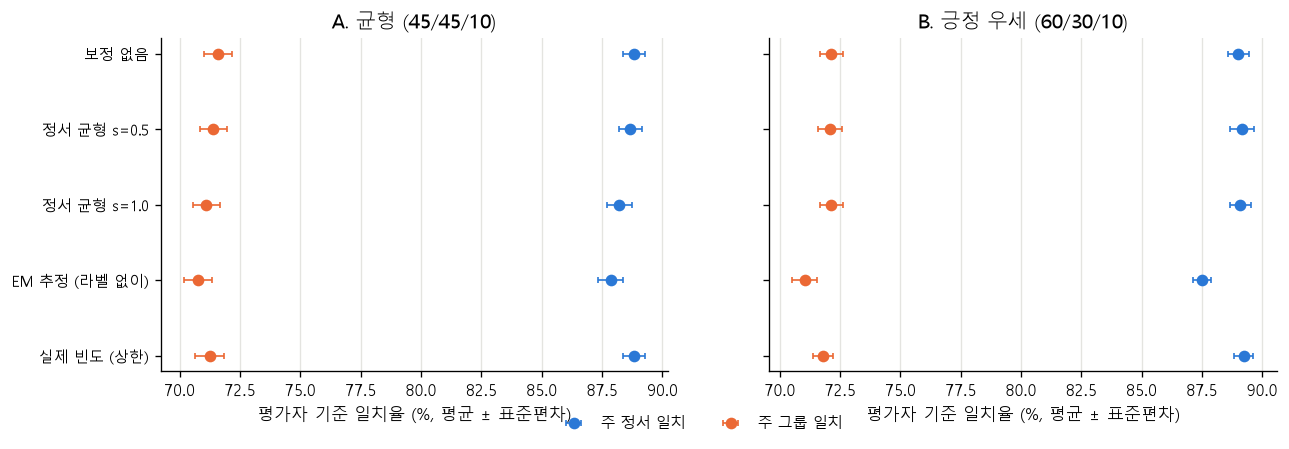

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
meths = list(methods_for(S["pt"][:2], np.arange(2)).keys())
y = np.arange(len(meths))[::-1]
for ax, scen in zip(axes, SCEN):
    t = shift[shift["시나리오"] == scen].groupby("방법", sort=False)[["주 정서 일치", "주 그룹 일치"]].agg(["mean", "std"]).loc[meths]
    for k, (col, color) in enumerate([("주 정서 일치", SERIES[0]), ("주 그룹 일치", SERIES[1])]):
        ax.errorbar(t[(col, "mean")] * 100, y, xerr=t[(col, "std")] * 100, fmt="o", ms=6, color=color,
                    ecolor=color, elinewidth=1, capsize=2, label=col)
    ax.set_yticks(y, meths, fontsize=9)
    ax.set_title(scen)
    ax.set_xlabel("평가자 기준 일치율 (%, 평균 ± 표준편차)")
    ax.grid(axis="x", color="#e4e4e0", lw=0.8)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, fontsize=9, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
save_fig(fig, FIG / "prior_correction_shift.png")
plt.show()

**결과 해석**

- 분포를 바꾼 가상 데이터에서도 **보정의 이득은 거의 없다**.
  - 균형(45/45/10): 보정 없음이 주 정서 일치 88.8%로 가장 높거나 같다.
  - 긍정 우세(60/30/10): 정서 균형 보정이 89.1~89.2%로 보정 없음(89.0%)과 사실상 같다.
- 이유는 **모델이 사전확률보다 글 내용에 강하게 반응하기 때문**이다. 긍정 우세 시나리오에서 보정 없이도 예측 긍정 비율이 59.9%로 실제(60%)를 따라갔다.
- **EM 보정은 해롭다**: 긍정 우세에서 예측 긍정 비율이 68.0%로 지나치게 늘고, 44개 감정 macro-F1이 0.567 → 0.481로 떨어진다. EM은 ‘사전확률만 바뀐다’는 가정에 기대는데, 이 모델은 그 가정과 맞지 않게 이미 분포 변화를 반영한다.
- 실제 빈도를 알고 보정한 상한도 보정 없음보다 낫지 않다.

### 5.3 서비스 데이터의 감정 빈도 추정

일기의 실제 감정 분포를 알면 보정 목표로 쓸 수 있다. 라벨 없이 추정하는 두 방법을 각 시나리오(20회 반복)에서 비교한다.
- **EM**: 사전확률 이동(prior shift) 가정 하의 표준 방법
- **확률 평균**: 모델 확률을 그대로 평균

오차는 44개 라벨의 실제 양성 비율과의 평균 절대 차이다.

In [10]:
rng = np.random.default_rng(1)
rows = []
for scen, shares in SCEN.items():
    for r in range(20):
        idx = np.concatenate([rng.choice(pools[v], int(round(5000 * s)), replace=True) for v, s in zip(VALENCES, shares)])
        p, true_pi = S["pt"][idx], Y["test"][idx].mean(0)
        rows.append({"시나리오": scen, "학습 빈도 그대로": np.abs(PI_TRAIN - true_pi).mean(),
                     "EM 추정": np.abs(estimate_priors_em(p, PI_TRAIN) - true_pi).mean(),
                     "확률 평균": np.abs(p.mean(0) - true_pi).mean()})
est = pd.DataFrame(rows).groupby("시나리오", sort=False).agg(["mean", "std"])
display(est.round(4))

학습 빈도 그대로           EM 추정           확률 평균        
                         mean     std    mean     std    mean     std
시나리오                                                                 
A. 균형 (45/45/10)       0.0186  0.0013  0.0306  0.0020  0.0081  0.0006
B. 긍정 우세 (60/30/10)    0.0592  0.0013  0.0705  0.0023  0.0088  0.0006

**결과 해석**

- 서비스 데이터의 감정 빈도를 추정할 때는 **모델 확률의 단순 평균이 가장 정확하다**. 라벨 빈도 평균 오차는 0.008~0.009다.
- 학습 빈도를 그대로 쓰면 0.019~0.059, EM은 0.031~0.071로 더 나쁘다.
- 따라서 일기가 쌓이면 ‘사용자 일기 전체의 감정 분포’는 모델 확률의 평균으로 보면 된다. 이를 다시 보정 목표로 쓸 필요는 크지 않다(5.2절).

## 6. 가상 일기에 적용

개발자가 쓴 가상 일기 12개(실제 사용자 일기 아님)의 주 정서·주 그룹이 보정 전후에 어떻게 바뀌는지 본다. 일기 12개로는 EM 추정이 불안정하므로 ‘정서 균형’만 적용한다.

In [11]:
import torch
from src.emotion.predict import EmotionPredictor

demo = load_json(P.configs / "demo_diaries.json")["diaries"]
texts = [d["text"] for d in demo]
dp = []
for m in S["members"]:
    info = json.loads((EMO_OUT / m / "metrics.json").read_text(encoding="utf-8"))
    pred = EmotionPredictor(P.repo_root / info["checkpoint_dir"])
    dp.append(pred.predict_proba(texts))
    del pred
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
dp = np.mean(dp, 0)
dp_adj = adjust_priors(dp, PI_TRAIN, target_priors_valence_balanced(PI_TRAIN, H), PP["prior_correction"]["strength"])
rows = []
for k, d in enumerate(demo):
    v0, v1 = valence_scores(dp[k], H)[0], valence_scores(dp_adj[k], H)[0]
    g0, g1 = group_scores(dp[k], H)[0][:10], group_scores(dp_adj[k], H)[0][:10]
    rows.append({"id": d["id"], "의도": d["intended"],
                 "정서 점수 전 (긍/부/중)": " / ".join(f"{x:.2f}" for x in v0), "주 정서 전": VAL_KO[VALENCES[v0.argmax()]],
                 "주 그룹 전": H["group_names"][g0.argmax()],
                 "정서 점수 후 (긍/부/중)": " / ".join(f"{x:.2f}" for x in v1), "주 정서 후": VAL_KO[VALENCES[v1.argmax()]],
                 "주 그룹 후": H["group_names"][g1.argmax()]})
display(pd.DataFrame(rows))

,id,의도,정서 점수 전 (긍/부/중),주 정서 전,주 그룹 전,정서 점수 후 (긍/부/중),주 정서 후,주 그룹 후
0,d01,joy,0.97 / 0.03 / 0.02,긍정,기쁨·즐거움,0.98 / 0.02 / 0.02,긍정,기쁨·즐거움
1,d02,warmth,0.90 / 0.05 / 0.02,긍정,기쁨·즐거움,0.92 / 0.04 / 0.02,긍정,기쁨·즐거움
2,d03,calm,0.89 / 0.15 / 0.10,긍정,기쁨·즐거움,0.91 / 0.13 / 0.10,긍정,기쁨·즐거움
3,d04,curiosity,0.96 / 0.03 / 0.03,긍정,기대·호기심,0.97 / 0.02 / 0.03,긍정,기대·호기심
4,d05,anger,0.04 / 0.97 / 0.01,부정,분노·불만,0.05 / 0.96 / 0.01,부정,분노·불만
5,d06,sadness,0.15 / 0.95 / 0.03,부정,슬픔·상실,0.19 / 0.94 / 0.03,부정,슬픔·상실
6,d07,anxiety,0.14 / 0.89 / 0.03,부정,불안·당황,0.18 / 0.86 / 0.03,부정,불안·당황
7,d08,fatigue,0.16 / 0.93 / 0.06,부정,지침·무기력,0.20 / 0.92 / 0.06,부정,지침·무기력
8,d09,shame,0.53 / 0.79 / 0.07,부정,슬픔·상실,0.60 / 0.76 / 0.07,부정,슬픔·상실
9,d10,contempt,0.18 / 0.96 / 0.01,부정,슬픔·상실,0.22 / 0.95 / 0.01,부정,분노·불만


**결과 해석**

- 감정이 분명한 가상 일기 10개는 보정 전후의 주 정서·주 그룹이 대부분 같다.
- 바뀐 경우:
  - **담담한 일기(d11)**: 주 정서 부정 → 긍정(긍정 0.53·부정 0.55 → 긍정 0.59·부정 0.50), 주 그룹 지침·무기력 → 평온·안심. 근거가 약한 글에서는 KOTE의 부정 사전확률이 판단을 좌우하므로, 보정이 의도대로 작동한 사례다.
  - **혐오 일기(d10)**: 주 그룹 슬픔·상실 → 분노·불만. 정서(부정)는 그대로다.
- 즉 보정은 **감정 근거가 약한 글에만 영향을 준다**. 일기에는 이런 글이 댓글보다 많을 수 있지만, 실제 일기로 확인하기 전에는 효과를 단정할 수 없다.

## 7. 결론

**A.X Encoder**
- 최신 한국어 인코더지만 이 과제에서는 KcELECTRA보다 낮았다(그룹 0.696 vs 0.714). 서비스용 앙상블은 **KcELECTRA + KLUE-large**를 유지한다.

**라벨 묶기 (권장)**
- 44개 감정 → 10개 그룹 + 없음 → 3개 정서의 계층을 후처리로 제공한다(`postprocess.py`).
- 3개 정서 macro-F1 **0.795**, 주 정서 일치 **91.3%**. 서비스 UI(오늘의 정서)와 행성 외형(그룹 색)에 바로 쓸 수 있다.

**부정 편향 보정 (기본값: 끔)**
- 데이터는 부정 쪽으로 기울어 있지만, 모델 예측은 글 내용을 따라가서 과하게 부정적이지 않다.
- 사전확률 보정은 분포가 바뀐 가상 데이터에서도 이득이 거의 없었고, EM 보정은 해로웠다. 그래서 설정의 기본값은 ‘보정 끔’으로 둔다.
- 감정 근거가 약한 글(담담한 일기)에서는 보정이 의미 있게 작동한다. 실제 일기 데이터로 확인한 뒤 ‘정서 균형, 강도 0.5’를 켤지 정한다. 이 설정의 비용은 KOTE test 기준 주 정서 일치 −0.2%p로 작다.
- 사용자 일기 전체의 감정 분포는 모델 확률의 평균으로 추정한다.

**다음 단계**
1. 실제 일기 소량(동의) 수집 → 담담한 일기에서 보정 효과 확인, 정서·그룹 평가
2. ‘중립’(담담함) 인식 개선: 정서 중 F1이 가장 낮음(0.56)
3. 행성 매핑에 정서 단계 반영(예: 정서로 행성 전체 톤을 정하고, 그룹으로 색을 정함)